# Notebook 4 — Part 2 (the extension): can a quantum *kernel* beat classical machine learning?

**What this notebook covers**

1. What changes in Part 2
2. What is a kernel?
3. The two quantum kernels
4. The known weakness of quantum kernels, seen in our own circuit
5. The competitors
6. The planned results
7. A follow-up we added after seeing them
8. Are the probabilities themselves any good?
9. Was there ever room for an advantage?
10. Verdict

Code: `src/qon/kernels.py`, `src/qon/kernel_backtest.py`, `scripts/05_run_part2_kernels.py`.

In [1]:
# Set-up: make the project's code importable and keep the output tidy.
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 60); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
%matplotlib inline

## 1. What changes in Part 2

In Part 1 the learning algorithm stayed the same and its **inputs** changed (classical or quantum features).

Part 2 turns that around. The inputs are always the same 98 classical numbers. What changes is the **learning algorithm**:

```
Part 1:   [classical inputs  OR  quantum features]  ->  the same ML models       ->  p(fill)
Part 2:    classical inputs                         ->  [classical ML  OR  quantum kernel]  ->  p(fill)
```

The question: is there any advantage in estimating p(fill) with a *quantum kernel* instead of classical machine learning?

## 2. What is a kernel?

A **kernel** is a similarity score between two quote requests: near 1 if they are alike, near 0 if they are not.

A **kernel machine** (we use the standard one, a *support vector machine* or SVM) predicts the outcome of a new request by looking at the outcomes of the past requests most similar to it. Everything depends on how "similar" is defined:

| Kernel | How similarity is measured |
|---|---|
| linear | the plain dot product of the two input rows |
| RBF (classical workhorse) | falls off smoothly with the distance between the two rows |

An SVM only outputs a score, not a probability. To get p(fill) we use the standard fix, *Platt scaling*: fit a logistic curve that turns scores into probabilities.

## 3. The two quantum kernels

| Kernel | How similarity is measured | Circuits needed on real hardware |
|---|---|---|
| **Fidelity quantum kernel (FQK)** | load each request into a quantum state with our circuit; similarity = how much the two states **overlap** | one per **pair** of requests: about a million for one training window |
| **Projected quantum kernel (PQK)** | load each request into a quantum state, **measure every qubit** (the 327 numbers of Part 1), then apply an RBF kernel to those measurements | one per request: the same circuits as Part 1 |

The fidelity kernel is the textbook quantum kernel. The projected kernel was proposed by Huang et al. (2021) to fix its problems, and it is the kernel version of HSBC's "projected quantum feature map".

The table's last column decides what could ever run on a real chip: the projected kernel reuses the circuits of Part 1, while the fidelity kernel needs a separate circuit for every pair of requests, far beyond any free hardware budget. Here we compute both exactly on a laptop.

**How can a laptop compute overlaps of 109-qubit states?** A shallow circuit on a line of qubits creates very little entanglement, so its state can be stored exactly as a chain of small tables (a *matrix product state*) instead of 2¹⁰⁹ numbers. `tests/test_kernels.py` checks the result against Qiskit.

## 4. The known weakness of quantum kernels, seen in our own circuit

Quantum kernels with many qubits suffer from **exponential concentration**: two *different* inputs are loaded into states that hardly overlap at all, so every similarity is practically zero. A kernel in which nothing is similar to anything carries no information.

The cure is to shrink the rotation scale `alpha` (the kernel's *bandwidth*), so that different inputs produce states that still overlap. We screened four values of alpha **on calibration data only**: train on 800 calibration requests, test on the last 10 calibration days.

,typical similarity of two different requests,AUC on held-out calibration days
alpha,,
1.0000,3.3e-16,0.4429
0.3000,2.5e-02,0.4453
0.1000,6.6e-01,0.4479
0.0300,9.6e-01,0.4266


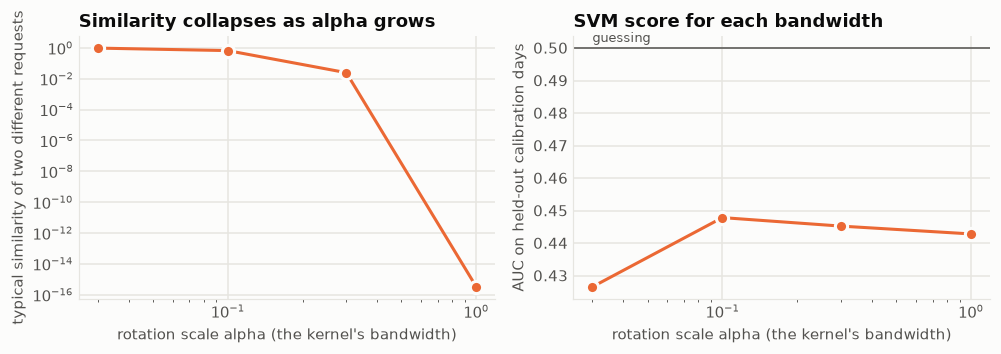

In [2]:
import json
from qon import config as C
from qon.analysis import load, part2_table, fig_part2, fig_fqk_screen, METHOD_LABEL
screen = pd.read_csv(C.TABLES / "part2_fqk_alpha_screen.csv")
meta = json.loads((C.TABLES / "part2_meta.json").read_text())
fig_fqk_screen(screen);
s = screen[["alpha", "median_similarity", "validation_auc"]].sort_values("alpha", ascending=False).copy()
s["median_similarity"] = s["median_similarity"].map(lambda v: f"{v:.1e}")
s.columns = ["alpha", "typical similarity of two different requests", "AUC on held-out calibration days"]
s.set_index("alpha")

**How to read the left chart.** At `alpha = 1` (the setting of Part 1) the typical similarity between two different requests is about 10⁻¹⁶: for practical purposes zero. Every request looks unrelated to every other one. That is exponential concentration, in our own circuit. As alpha shrinks the similarities become usable; shrink it too far (0.03) and the opposite happens: everything looks 96% the same.

**How to read the right chart.** None of the four bandwidths produced a working SVM on the held-out calibration days: all scores are *below* 0.5. Our rule, fixed in advance, was to take the best, which is `alpha = 0.1`. Remember this warning sign; section 6 shows it was not specific to the quantum kernel.

## 5. The competitors

Everyone gets the same inputs and the same rolling backtest as Part 1. Because kernel machines compare all pairs of events, Part 2 uses an evenly thinned sample (50 requests per day) and a training window of 800. The four classical models are re-run on exactly that sample, so the comparison is like for like.

| Family | Method |
|---|---|
| classical machine learning | logistic regression, random forest, gradient boosting, neural network |
| classical kernel machines | SVM with a linear kernel, SVM with an RBF kernel |
| quantum kernel machines | SVM with the projected quantum kernel, on a perfect chip and on the noisy simulated chip |
| | SVM with the fidelity quantum kernel, exact, and with every overlap estimated from 4,096 shots |

## 6. The planned results

3,400 test requests, 10 methods, 68 test days; fidelity kernel bandwidth chosen on calibration data: alpha = 0.1


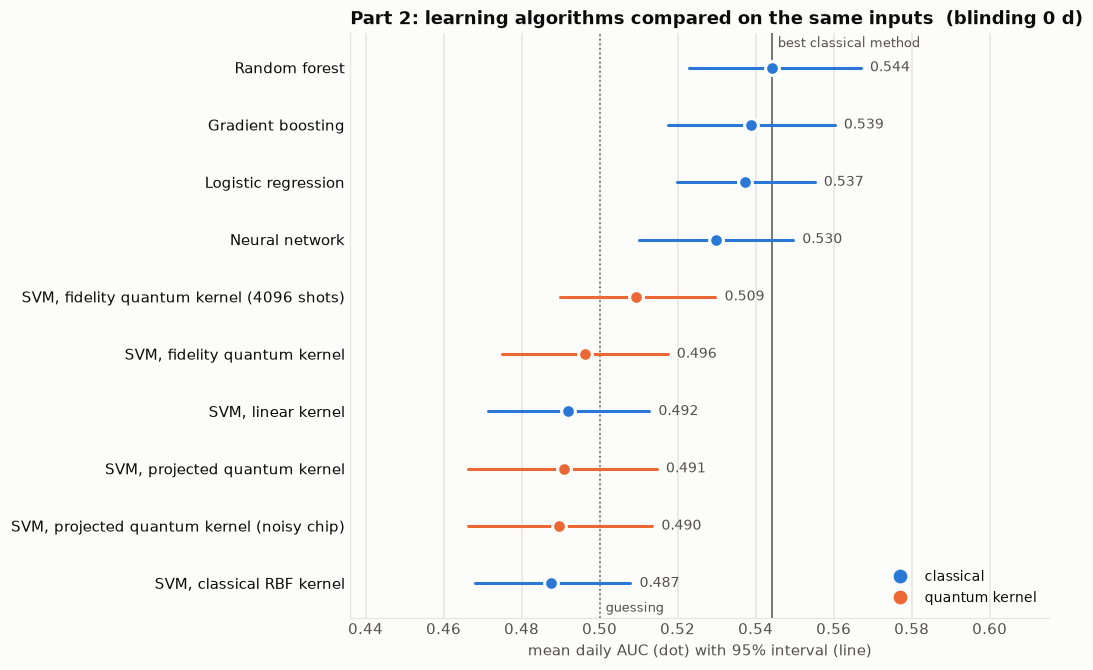

In [3]:
pred2 = load("part2_predictions")
print(f"{pred2['row'].nunique():,} test requests, {pred2['model'].nunique()} methods, {pred2['day'].nunique()} test days; "
      f"fidelity kernel bandwidth chosen on calibration data: alpha = {meta['alpha_star']}")
fig_part2(pred2, blinding=0);

In [4]:
def show(b):
    t = part2_table(pred2, b)
    base = t.attrs["baseline"]
    out = t[["family", "mean_auc", "ci_low", "ci_high", f"diff_vs_{base}", "diff_ci_low", "diff_ci_high", "significant"]].copy()
    out.index = [METHOD_LABEL[m] for m in out.index]
    out.columns = ["family", "mean daily AUC", "95% low", "95% high", f"difference to best classical ({base})",
                   "diff 95% low", "diff 95% high", "real difference?"]
    out.index.name = f"blinding = {b} day(s)"
    return out.round(4)
show(0)

,family,mean daily AUC,95% low,95% high,difference to best classical (RF),diff 95% low,diff 95% high,real difference?
blinding = 0 day(s),,,,,,,,
Random forest,classical,0.5441,0.5228,0.5670,0.0000,0.0000,0.0000,False
Gradient boosting,classical,0.5388,0.5175,0.5603,-0.0054,-0.0235,0.0140,False
Logistic regression,classical,0.5373,0.5199,0.5551,-0.0068,-0.0299,0.0160,False
Neural network,classical,0.5298,0.5100,0.5496,-0.0143,-0.0377,0.0068,False
"SVM, fidelity quantum kernel (4096 shots)",quantum,0.5094,0.4897,0.5297,-0.0347,-0.0643,-0.0070,True
"SVM, fidelity quantum kernel",quantum,0.4962,0.4750,0.5174,-0.0479,-0.0760,-0.0211,True
"SVM, linear kernel",classical,0.4918,0.4713,0.5127,-0.0523,-0.0849,-0.0217,True
"SVM, projected quantum kernel",quantum,0.4909,0.4663,0.5147,-0.0532,-0.0885,-0.0204,True
"SVM, projected quantum kernel (noisy chip)",quantum,0.4897,0.4664,0.5135,-0.0544,-0.0883,-0.0221,True


**How to read it.** Blue dots are classical methods, orange dots are quantum kernels; the vertical line marks the best classical method.

**Result of the planned comparison: no quantum kernel advantage.** All four quantum kernel machines score about 0.49–0.51, which is guessing, and significantly below the best classical model.

**But look at the classical kernel machines.** The SVM with the ordinary RBF kernel and the SVM with a linear kernel are *also* at 0.49. A linear SVM and logistic regression are close cousins (both draw one straight line), yet logistic regression scores 0.537 on the same data. So the kernels are not the problem. **The SVM is.**

Why does the SVM fail here? An SVM tries to draw a boundary between "filled" and "not filled" and does not care how confident it should be. When the signal is very weak and one outcome is more common (63% of quotes are not filled), the best boundary is simply "call everything not filled". The scores it produces are then meaningless. Methods that fit a probability or a smooth score (logistic regression, trees) do not have this problem.

That makes the planned comparison a fair "no advantage", but an uninformative one: it cannot tell a good kernel from a bad one. So we added a follow-up.

## 7. A follow-up we added after seeing these results

**This section was not in the plan that was frozen beforehand** ([PREREGISTRATION.md](../PREREGISTRATION.md), section 9). We report it because it is more informative, and we label it so that nobody mistakes it for a pre-planned test.

We keep every kernel exactly as it was and replace the SVM by **kernel ridge regression**: instead of drawing a boundary, it fits a smooth score to all training events at once. Same kernels, same data, same backtest; the smoothing strength is chosen by cross-validation inside the training window, as before.

,family,mean daily AUC,95% low,95% high,"difference to best classical (Kernel ridge, linear kernel)",diff 95% low,diff 95% high,real difference?
"FOLLOW-UP, blinding = 0 day(s)",,,,,,,,
"Kernel ridge, linear kernel",classical,0.5455,0.5277,0.5627,0.0000,0.0000,0.0000,False
Random forest,classical,0.5441,0.5228,0.5670,-0.0014,-0.0247,0.0221,False
"Kernel ridge, classical RBF kernel",classical,0.5410,0.5239,0.5578,-0.0045,-0.0213,0.0126,False
Gradient boosting,classical,0.5388,0.5175,0.5603,-0.0068,-0.0315,0.0170,False
Logistic regression,classical,0.5373,0.5199,0.5551,-0.0082,-0.0198,0.0038,False
"Kernel ridge, fidelity quantum kernel",quantum,0.5371,0.5198,0.5537,-0.0084,-0.0203,0.0031,False
"Kernel ridge, fidelity quantum kernel (4096 shots)",quantum,0.5338,0.5159,0.5517,-0.0117,-0.0245,0.0002,False
"Kernel ridge, projected quantum kernel (noisy chip)",quantum,0.5306,0.5095,0.5531,-0.0149,-0.0374,0.0094,False
"Kernel ridge, projected quantum kernel",quantum,0.5301,0.5091,0.5522,-0.0154,-0.0376,0.0082,False


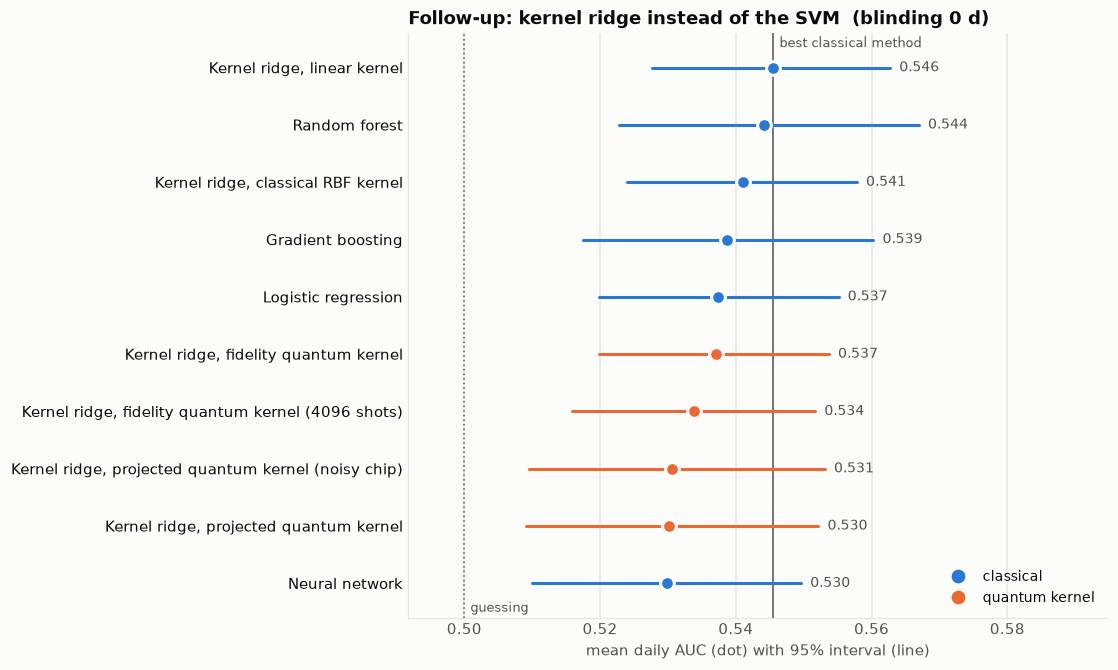

In [5]:
follow = pd.concat([pred2[~pred2["model"].str.startswith("SVM")], load("part2_followup_predictions")])
fig_part2(follow, blinding=0, name="part2_followup_methods", title="Follow-up: kernel ridge instead of the SVM");
def show_follow(b):
    t = part2_table(follow, b)
    base = t.attrs["baseline"]
    out = t[["family", "mean_auc", "ci_low", "ci_high", f"diff_vs_{base}", "diff_ci_low", "diff_ci_high", "significant"]].copy()
    out.index = [METHOD_LABEL[m] for m in out.index]
    out.columns = ["family", "mean daily AUC", "95% low", "95% high", f"difference to best classical ({METHOD_LABEL[base]})",
                   "diff 95% low", "diff 95% high", "real difference?"]
    out.index.name = f"FOLLOW-UP, blinding = {b} day(s)"
    return out.round(4)
show_follow(0)

**With a learning method that suits a weak signal, the kernels work**, and the picture becomes clear:

* Kernel machines now score like the classical models (about 0.53–0.545).
* The best performers are the plainest, **linear** methods: kernel ridge with a linear kernel at blinding 0 and 1, logistic regression at blinding 4.
* The quantum kernels sit in the lower half of the pack. At blinding 0 and 1 the fidelity kernel does a little better than the projected kernel. **None of them beats the best classical method**; at blinding 0 none of the differences is statistically clear either way.
* Estimating the fidelity kernel from 4,096 shots, or computing the projected kernel on a noisy chip, changes little.

The tables for blinding 1 and 4 tell the same story: quantum kernels are never ahead, and in several cells they are significantly behind.

In [6]:
display(show_follow(1)); display(show_follow(4))

,family,mean daily AUC,95% low,95% high,"difference to best classical (Kernel ridge, linear kernel)",diff 95% low,diff 95% high,real difference?
"FOLLOW-UP, blinding = 1 day(s)",,,,,,,,
"Kernel ridge, linear kernel",classical,0.5455,0.5271,0.5633,0.0000,0.0000,0.0000,False
Gradient boosting,classical,0.5420,0.5221,0.5644,-0.0034,-0.0267,0.0212,False
Logistic regression,classical,0.5372,0.5193,0.5540,-0.0083,-0.0161,-0.0003,True
"Kernel ridge, fidelity quantum kernel (4096 shots)",quantum,0.5343,0.5158,0.5527,-0.0111,-0.0236,0.0008,False
Neural network,classical,0.5329,0.5121,0.5521,-0.0126,-0.0308,0.0056,False
"Kernel ridge, fidelity quantum kernel",quantum,0.5326,0.5148,0.5501,-0.0128,-0.0244,-0.0024,True
Random forest,classical,0.5320,0.5106,0.5532,-0.0135,-0.0335,0.0077,False
"Kernel ridge, classical RBF kernel",classical,0.5308,0.5119,0.5509,-0.0146,-0.0322,0.0035,False
"Kernel ridge, projected quantum kernel (noisy chip)",quantum,0.5231,0.5038,0.5428,-0.0224,-0.0415,-0.0023,True


,family,mean daily AUC,95% low,95% high,difference to best classical (Logistic regression),diff 95% low,diff 95% high,real difference?
"FOLLOW-UP, blinding = 4 day(s)",,,,,,,,
Logistic regression,classical,0.5415,0.5247,0.5583,0.0000,0.0000,0.0000,False
"Kernel ridge, linear kernel",classical,0.5335,0.5173,0.5501,-0.0080,-0.0179,0.0018,False
Neural network,classical,0.5320,0.5137,0.5494,-0.0095,-0.0322,0.0120,False
"Kernel ridge, classical RBF kernel",classical,0.5239,0.5044,0.5436,-0.0176,-0.0364,0.0013,False
"Kernel ridge, projected quantum kernel (noisy chip)",quantum,0.5236,0.5046,0.5426,-0.0179,-0.0368,0.0007,False
"Kernel ridge, projected quantum kernel",quantum,0.5233,0.5042,0.5418,-0.0182,-0.0370,-0.0001,True
"Kernel ridge, fidelity quantum kernel",quantum,0.5222,0.5034,0.5397,-0.0193,-0.0340,-0.0054,True
Random forest,classical,0.5200,0.5001,0.5395,-0.0215,-0.0388,-0.0040,True
"Kernel ridge, fidelity quantum kernel (4096 shots)",quantum,0.5145,0.4963,0.5332,-0.0270,-0.0459,-0.0091,True


For completeness, the planned SVM comparison at the other two blindings:

In [7]:
display(show(1)); display(show(4))

,family,mean daily AUC,95% low,95% high,difference to best classical (XGB),diff 95% low,diff 95% high,real difference?
blinding = 1 day(s),,,,,,,,
Gradient boosting,classical,0.5420,0.5221,0.5644,0.0000,0.0000,0.0000,False
Logistic regression,classical,0.5372,0.5193,0.5540,-0.0049,-0.0277,0.0173,False
Neural network,classical,0.5329,0.5121,0.5521,-0.0092,-0.0332,0.0151,False
Random forest,classical,0.5320,0.5106,0.5532,-0.0101,-0.0279,0.0087,False
"SVM, linear kernel",classical,0.5185,0.4960,0.5416,-0.0235,-0.0570,0.0073,False
"SVM, classical RBF kernel",classical,0.5095,0.4894,0.5294,-0.0326,-0.0583,-0.0073,True
"SVM, fidelity quantum kernel (4096 shots)",quantum,0.5074,0.4868,0.5286,-0.0346,-0.0635,-0.0060,True
"SVM, projected quantum kernel (noisy chip)",quantum,0.5061,0.4858,0.5280,-0.0359,-0.0596,-0.0103,True
"SVM, fidelity quantum kernel",quantum,0.5008,0.4799,0.5212,-0.0412,-0.0688,-0.0148,True


,family,mean daily AUC,95% low,95% high,difference to best classical (LR),diff 95% low,diff 95% high,real difference?
blinding = 4 day(s),,,,,,,,
Logistic regression,classical,0.5415,0.5247,0.5583,0.0000,0.0000,0.0000,False
Neural network,classical,0.5320,0.5137,0.5494,-0.0095,-0.0322,0.0120,False
Random forest,classical,0.5200,0.5001,0.5395,-0.0215,-0.0388,-0.0040,True
"SVM, classical RBF kernel",classical,0.5196,0.4990,0.5397,-0.0219,-0.0399,-0.0035,True
"SVM, fidelity quantum kernel (4096 shots)",quantum,0.5063,0.4868,0.5257,-0.0352,-0.0596,-0.0126,True
Gradient boosting,classical,0.5055,0.4850,0.5264,-0.0360,-0.0575,-0.0134,True
"SVM, projected quantum kernel",quantum,0.5055,0.4849,0.5263,-0.0360,-0.0577,-0.0143,True
"SVM, projected quantum kernel (noisy chip)",quantum,0.5055,0.4853,0.5265,-0.0360,-0.0569,-0.0144,True
"SVM, fidelity quantum kernel",quantum,0.4984,0.4753,0.5215,-0.0431,-0.0699,-0.0185,True


## 8. Are the probabilities themselves any good?

AUC only checks the *ranking* of requests. The project is about p(fill), so the probabilities should also be sensible numbers. The **Brier score** measures that (the average squared error of the predicted probability; lower is better). The yardstick is the score of always predicting the overall fill rate.

In [8]:
t = part2_table(pd.concat([pred2, load("part2_followup_predictions")]), 0)
always = pred2[pred2["blinding"] == 0].drop_duplicates("row")["filled"].mean()
b = t[["family", "mean_auc", "brier"]].copy()
b.index = [METHOD_LABEL[m] for m in b.index]
b.columns = ["family", "mean daily AUC", "Brier score (lower is better)"]
print(f"yardstick: always predicting the fill rate {always:.3f} gives a Brier score of {always * (1 - always):.4f}")
b.sort_values("Brier score (lower is better)").round(4)

yardstick: always predicting the fill rate 0.376 gives a Brier score of 0.2345


,family,mean daily AUC,Brier score (lower is better)
"SVM, classical RBF kernel",classical,0.4875,0.2354
"SVM, linear kernel",classical,0.4918,0.2355
"SVM, fidelity quantum kernel",quantum,0.4962,0.2355
"SVM, fidelity quantum kernel (4096 shots)",quantum,0.5094,0.2356
Random forest,classical,0.5441,0.2358
"SVM, projected quantum kernel (noisy chip)",quantum,0.4897,0.2358
"SVM, projected quantum kernel",quantum,0.4909,0.2358
"Kernel ridge, fidelity quantum kernel",quantum,0.5371,0.2364
"Kernel ridge, fidelity quantum kernel (4096 shots)",quantum,0.5338,0.2372
"Kernel ridge, projected quantum kernel (noisy chip)",quantum,0.5306,0.2381


**A sobering result: as probabilities, nothing beats simply quoting the average fill rate.** Every method's Brier score is slightly *worse* than the yardstick. The models can rank requests a little better than chance (AUC about 0.54), but the signal is too weak for their individual probabilities to improve on "about 37%, every time". (The yardstick uses the test window's own fill rate, which one would not know in advance, so it is a slightly generous benchmark.)

This is a property of the prediction problem, not of any one method, and it applies to classical and quantum methods alike. It is also a reminder of how hard HSBC's task is: an AUC anywhere near 0.97, as reported for their hardware features, would be extraordinary.

## 9. Was there ever room for an advantage?

Two diagnostics from the research literature, computed on the last training window before the test period (so no test data is involved).

* **Alignment** (−1 to 1): does "similar according to the kernel" agree with "same outcome"? Higher is better. A kernel that carries no information scores about 0.
* **Geometric difference** to the classical RBF kernel (Huang et al. 2021): how differently the quantum kernel arranges the same data. A value near 1 means the classical kernel can already express everything the quantum kernel can, so no advantage is possible. Only a large value (comparable to the square root of the number of training events, here about 28) leaves room for an advantage, and even then it is not guaranteed.

In [9]:
diag = pd.read_csv(C.TABLES / "part2_kernel_diagnostics.csv")
d = diag[["kernel", "median", "alignment", "geometric_difference_vs_RBF"]].copy()
d["kernel"] = d["kernel"].map(lambda k: METHOD_LABEL.get(k, "SVM, fidelity quantum kernel with alpha = 1 (not tuned)"))
d["median"] = d["median"].map(lambda v: f"{v:.1e}")
d.columns = ["kernel", "typical similarity of two different requests", "alignment with fills", "geometric difference to classical RBF"]
print(f"square root of the training-set size: {meta['sqrt_n_train']:.1f}")
d.set_index("kernel").round(4)

square root of the training-set size: 28.3


,typical similarity of two different requests,alignment with fills,geometric difference to classical RBF
kernel,,,
"SVM, fidelity quantum kernel",6.8e-01,0.0042,3.1505
"SVM, classical RBF kernel",3.7e-01,0.0068,NaN
"SVM, projected quantum kernel",3.7e-01,0.0091,6.1821
"SVM, projected quantum kernel (noisy chip)",3.7e-01,0.0090,6.3683
"SVM, fidelity quantum kernel with alpha = 1 (not tuned)",1.2e-15,0.0354,13.1260


**How to read it**

* **Alignment is tiny for every kernel**, classical or quantum: "similar inputs" only weakly means "same outcome". That is the weak signal again. (The 0.035 of the untuned fidelity kernel is not a success: a matrix with ones on the diagonal and zeros elsewhere gets 1/√800 = 0.035 automatically.)
* **Geometric difference** is between about 3 and 13, well below the √N ≈ 28 that would signal real room for a quantum advantage. In Huang et al.'s terms, the classical kernel can already represent what these quantum kernels represent on this data.
* The largest value belongs to the untuned fidelity kernel (alpha = 1), which is the concentrated kernel that treats every request as unrelated to every other. Being *different* from the classical kernel is not the same as being *useful*.

## 10. Verdict

**Can a quantum kernel be used instead of classical machine learning to gain an advantage in estimating p(fill)? On this data: no.**

1. **Planned test (SVM):** no advantage. Every quantum kernel machine scored at guessing level. So did every classical kernel machine, which shows that the SVM, not the kernels, was failing.
2. **Follow-up (kernel ridge, added afterwards):** with a method that suits a weak signal the kernels work, and the quantum kernels score about the same as, or slightly below, the classical ones. The best performer is a plain linear method.
3. **The fidelity kernel only works when its bandwidth is shrunk**, and a quantum kernel with a small bandwidth behaves like an ordinary smooth classical kernel. At the natural setting (alpha = 1) it is exponentially concentrated and useless. This matches what the research literature predicts.
4. **There was little room for an advantage to begin with:** the geometric-difference test says the classical kernel can already express what the quantum kernels express.
5. **Practicality:** the fidelity kernel needs a circuit for every pair of requests (about a million per training window), which no free hardware budget allows. Only the projected kernel is realistic on hardware, and it is the weaker of the two here.

**What we cannot say:** that quantum kernels can never help with fill prediction. Our signal is weak, our fill label is a stand-in, we used one circuit design, and all of this is simulation. What we can say is that on real public bond data, with HSBC's circuit, we looked carefully and found no advantage.

**Next:** [Notebook 5](05_hardware_run_and_limitations.ipynb) — the hardware run that is still to do, and the full list of limitations.